In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import numpy as np

from random import randint

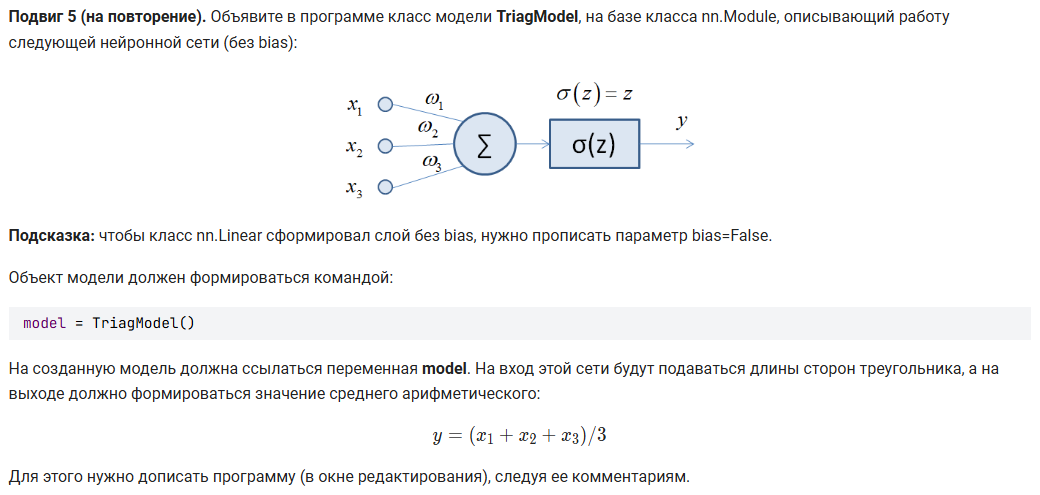

In [13]:
class TriagModel(nn.Module):
    def __init__(self, inp=3, outp=1):
        super().__init__()
        self.layer1 = nn.Linear(3, 1, bias=False)

    def forward(self, x):
        x = self.layer1(x)
        return x
    
np.random.seed(1)
torch.manual_seed(1)

total = 100
x_train = torch.randint(1, 10, (total, 3), dtype=torch.float32)
y_train = x_train.sum(dim=1) / 3

# здесь создавайте модель (model)
model = TriagModel()
model.train()
# переведите модель в режим обучения

lr = 0.01 # шаг обучения
N = 1000 # число итераций SGD

optimizer = optim.Adam(model.parameters(), lr=lr) # здесь сформируйте оптимизатор Adam с параметрами модели и шагом обучения lr
loss_func = nn.MSELoss() # здесь создайте функцию потерь с помощью класса nn.MSELoss

for _ in range(N):
    k = np.random.randint(0, total)
    # пропустите через модель k-й образ выборки x_train и вычислите прогноз predict
    predict = model(x_train[k]) 
    loss = loss_func(predict, y_train[k])  # вычислите значение функции потерь и сохраните результат в переменной loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    

C:\Users\z.kuznetsov\AppData\Local\miniconda3\envs\torch_env\Lib\site-packages\torch\nn\modules\loss.py:535: UserWarning: Using a target size (torch.Size([])) that is different to the input size (torch.Size([1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [16]:
x = torch.tensor([1,1,4], dtype=torch.float32)

model(x)

tensor([2.0000], grad_fn=<SqueezeBackward4>)

In [19]:
list(model.parameters())

[Parameter containing:
 tensor([[0.3333, 0.3333, 0.3333]], requires_grad=True)]

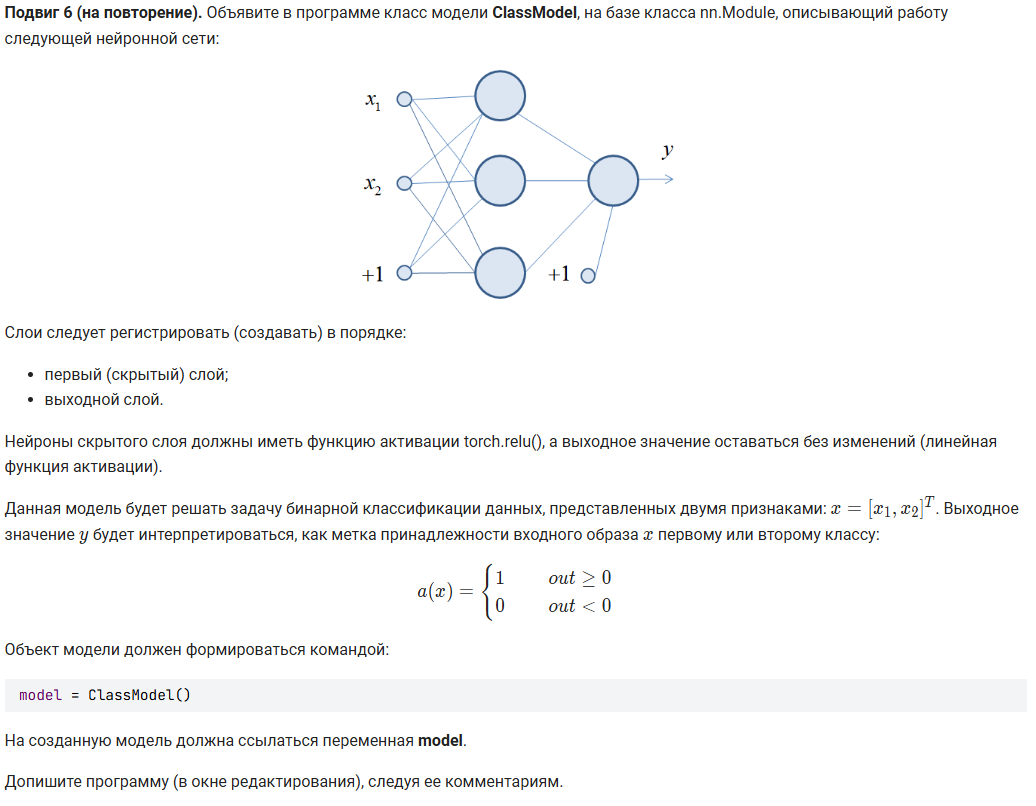

In [78]:
class ClassModel(nn.Module):
    def __init__(self, inp=2, hidden=3, outp=1):
        super().__init__()
        self.layer1 = nn.Linear(inp, hidden, bias=True)
        self.f_act = torch.relu
        self.layer2 = nn.Linear(hidden, outp, bias=True)

    def forward(self, x):
        x = self.layer1(x)
        x = self.f_act(x)
        x = self.layer2(x)
        return x
        

np.random.seed(1)
torch.manual_seed(1)

# обучающая выборка: x_train - входные значения; y_train - целевые значения
x_train = torch.tensor([(5.8, 1.2), (5.6, 1.5), (6.5, 1.5), (6.1, 1.3), (6.4, 1.3), (7.7, 2.0), (6.0, 1.8), (5.6, 1.3), (6.0, 1.6), (5.8, 1.9), (5.7, 2.0), (6.3, 1.5), (6.2, 1.8), (7.7, 2.3), (5.8, 1.2), (6.3, 1.8), (6.0, 1.0), (6.2, 1.3), (5.7, 1.3), (6.3, 1.9), (6.7, 2.5), (5.5, 1.2), (4.9, 1.0), (6.1, 1.4), (6.0, 1.6), (7.2, 2.5), (7.3, 1.8), (6.6, 1.4), (5.6, 2.0), (5.5, 1.0), (6.4, 2.2), (5.6, 1.3), (6.6, 1.3), (6.9, 2.1), (6.8, 2.1), (5.7, 1.3), (7.0, 1.4), (6.1, 1.4), (6.1, 1.8), (6.7, 1.7), (6.0, 1.5), (6.5, 1.8), (6.4, 1.5), (6.9, 1.5), (5.6, 1.3), (6.7, 1.4), (5.8, 1.9), (6.3, 1.3), (6.7, 2.1), (6.2, 2.3), (6.3, 2.4), (6.7, 1.8), (6.4, 2.3), (6.2, 1.5), (6.1, 1.4), (7.1, 2.1), (5.7, 1.0), (6.8, 1.4), (6.8, 2.3), (5.1, 1.1), (4.9, 1.7), (5.9, 1.8), (7.4, 1.9), (6.5, 2.0), (6.7, 1.5), (6.5, 2.0), (5.8, 1.0), (6.4, 2.1), (7.6, 2.1), (5.8, 2.4), (7.7, 2.2), (6.3, 1.5), (5.0, 1.0), (6.3, 1.6), (7.7, 2.3), (6.4, 1.9), (6.5, 2.2), (5.7, 1.2), (6.9, 2.3), (5.7, 1.3), (6.1, 1.2), (5.4, 1.5), (5.2, 1.4), (6.7, 2.3), (7.9, 2.0), (5.6, 1.1), (7.2, 1.8), (5.5, 1.3), (7.2, 1.6), (6.3, 2.5), (6.3, 1.8), (6.7, 2.4), (5.0, 1.0), (6.4, 1.8), (6.9, 2.3), (5.5, 1.3), (5.5, 1.1), (5.9, 1.5), (6.0, 1.5), (5.9, 1.8)])
y_train = torch.FloatTensor([0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1])

model = ClassModel() # здесь создавайте модель
model.train()
# переведите модель в режим обучения

total = x_train.size(0) # размер обучающей выборки
N = 1000 # число итераций алгоритма SGD
lr = 0.01 # шаг обучения

optimizer = optim.Adam(model.parameters(), lr=lr) # задайте оптимизатор Adam с шагом обучения lr=0.01
loss_func = nn.BCEWithLogitsLoss() # сформируйте функцию потерь (бинарную кросс-энтропию) с помощью класса nn.BCEWithLogitsLoss

for _ in range(N):
    k = np.random.randint(0, total)
    # пропустите через модель k-й образ выборки x_train и вычислите прогноз predict
    predict = model(x_train[k]).squeeze()
    loss = loss_func(predict, y_train[k]) # вычислите значение функции потерь и сохраните результат в переменной loss
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # выполните один шаг градиентного спуска так, как это было сделано в предыдущем подвиге

# переведите модель в режим эксплуатации
# прогоните через модель обучающую выборку и подсчитайте долю верных классификаций
# результат (долю верных классификаций) сохраните в переменной Q (в виде вещественного числа, а не тензора)
model.eval()

pred = torch.where(model(x_train)>0., torch.tensor(1), torch.tensor(0)).squeeze().float()
Q = (pred == y_train).sum().item() / pred.shape[0]
Q

0.89

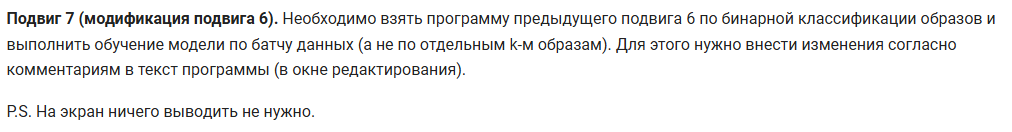

In [80]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# сюда скопируйте класс ClassModel из предыдущего подвига
class ClassModel(nn.Module):
    def __init__(self, inp=2, hidden=3, outp=1):
        super().__init__()
        self.layer1 = nn.Linear(inp, hidden, bias=True)
        self.f_act = torch.relu
        self.layer2 = nn.Linear(hidden, outp, bias=True)

    def forward(self, x):
        x = self.layer1(x)
        x = self.f_act(x)
        x = self.layer2(x)
        return x


np.random.seed(1)
torch.manual_seed(1)

# обучающая выборка: x_train - входные значения; y_train - целевые значения
x_train = torch.tensor([(5.8, 1.2), (5.6, 1.5), (6.5, 1.5), (6.1, 1.3), (6.4, 1.3), (7.7, 2.0), (6.0, 1.8), (5.6, 1.3), (6.0, 1.6), (5.8, 1.9), (5.7, 2.0), (6.3, 1.5), (6.2, 1.8), (7.7, 2.3), (5.8, 1.2), (6.3, 1.8), (6.0, 1.0), (6.2, 1.3), (5.7, 1.3), (6.3, 1.9), (6.7, 2.5), (5.5, 1.2), (4.9, 1.0), (6.1, 1.4), (6.0, 1.6), (7.2, 2.5), (7.3, 1.8), (6.6, 1.4), (5.6, 2.0), (5.5, 1.0), (6.4, 2.2), (5.6, 1.3), (6.6, 1.3), (6.9, 2.1), (6.8, 2.1), (5.7, 1.3), (7.0, 1.4), (6.1, 1.4), (6.1, 1.8), (6.7, 1.7), (6.0, 1.5), (6.5, 1.8), (6.4, 1.5), (6.9, 1.5), (5.6, 1.3), (6.7, 1.4), (5.8, 1.9), (6.3, 1.3), (6.7, 2.1), (6.2, 2.3), (6.3, 2.4), (6.7, 1.8), (6.4, 2.3), (6.2, 1.5), (6.1, 1.4), (7.1, 2.1), (5.7, 1.0), (6.8, 1.4), (6.8, 2.3), (5.1, 1.1), (4.9, 1.7), (5.9, 1.8), (7.4, 1.9), (6.5, 2.0), (6.7, 1.5), (6.5, 2.0), (5.8, 1.0), (6.4, 2.1), (7.6, 2.1), (5.8, 2.4), (7.7, 2.2), (6.3, 1.5), (5.0, 1.0), (6.3, 1.6), (7.7, 2.3), (6.4, 1.9), (6.5, 2.2), (5.7, 1.2), (6.9, 2.3), (5.7, 1.3), (6.1, 1.2), (5.4, 1.5), (5.2, 1.4), (6.7, 2.3), (7.9, 2.0), (5.6, 1.1), (7.2, 1.8), (5.5, 1.3), (7.2, 1.6), (6.3, 2.5), (6.3, 1.8), (6.7, 2.4), (5.0, 1.0), (6.4, 1.8), (6.9, 2.3), (5.5, 1.3), (5.5, 1.1), (5.9, 1.5), (6.0, 1.5), (5.9, 1.8)])
y_train = torch.FloatTensor([0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1])

model = ClassModel() # здесь создавайте модель
model.train()

total = x_train.size(0) # размер обучающей выборки
N = 1000 # число итераций алгоритма SGD
batch_size = 8 # размер мини-батча

optimizer = optim.Adam(model.parameters(), lr=0.01) # задайте оптимизатор Adam с шагом обучения lr=0.01
loss_func = nn.BCEWithLogitsLoss() # сформируйте функцию потерь (бинарную кросс-энтропию) с помощью класса nn.BCEWithLogitsLoss

for _ in range(N):
    idx = np.random.choice(total, batch_size, False) # выбор индексов образов в размере batch_size
    # с помощью списочной индексации отберите из выборки x_train образы согласно индексам списка idx
    # пропустите через модель батч образов выборки и вычислите батч прогнозов predict
    predict = model(x_train[idx]).squeeze()
    loss = loss_func(predict, y_train[idx]) # вычислите значение функции потерь и сохраните результат в переменной loss
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # выполните один шаг градиентного спуска так, как это было сделано в предыдущем подвиге

# переведите модель в режим эксплуатации
# прогоните через модель обучающую выборку и подсчитайте долю верных классификаций
# результат (долю верных классификаций) сохраните в переменной Q (в виде вещественного числа, а не тензора)
model.eval()

pred = torch.where(model(x_train)>0., torch.tensor(1), torch.tensor(0)).squeeze().float()
Q = (pred == y_train).sum().item() / pred.shape[0]
Q

0.93